# Life-stage polities
Each individual gets a polity for each stage of life (early: birth → first work, active: first work → last work, late: last work → death). The stage's Wikidata fields are tried in priority order; a location is matched to the Cliopatria polities that held it during the stage, by Wikipedia link first, coordinates otherwise, and only the smallest polity of the Cliopatria hierarchy is kept. Run on a sample, before any ingestion.

In [1]:
import json
import sys
from pathlib import Path
from urllib.parse import unquote

import duckdb
import polars as pl
from shapely import STRtree, make_valid, points
from shapely.geometry import shape

sys.path.insert(0, '../notebooks_analysis')
from style import show_table

DB_PATH = '../../data/cultura/cultura_enriched_v3.2.duckdb'  # read only
LIFE_LOCATIONS = Path('../../data/raw_data_from_wikidata/wikidata_extraction_scripts_v2/life_locations')
CLIOPATRIA = Path('../../data/cliopatria_data/cliopatria_V2/cliopatria_polities_only_v3.geojson')
SAMPLE_SIZE = 10_000
SEED = 42
EXAMPLES = ['Q36620', 'Q8963']  # Tycho Brahe and Johannes Kepler, added to the sample

PROPERTIES = {'P937': 'work_location', 'P551': 'residence', 'P108': 'employer', 'P69': 'educated_at', 'P39': 'position_held'}
SOURCES = {
    'place_of_birth': 'birthplace', 'educated_at': 'school', 'residence': 'residence', 'country_of_citizenship': 'citizenship',
    'work_location': 'work location', 'employer': 'employer', 'position_held': 'position held', 'place_of_death': 'deathplace',
}
STAGES = {'early': ('birth', 'first_work'), 'active': ('first_work', 'last_work'), 'late': ('last_work', 'death')}
RULES = {
    'early': [('place_of_birth', 'certain'), ('educated_at', 'certain'), ('residence', 'unsure'), ('country_of_citizenship', 'unsure'), ('work_location', 'unsure'), ('employer', 'unsure'), ('position_held', 'unsure'), ('place_of_death', 'unsure')],
    'active': [('work_location', 'certain'), ('employer', 'certain'), ('position_held', 'certain'), ('residence', 'certain'), ('educated_at', 'unsure'), ('country_of_citizenship', 'unsure'), ('place_of_birth', 'unsure'), ('place_of_death', 'unsure')],
    'late': [('place_of_death', 'certain'), ('residence', 'unsure'), ('work_location', 'unsure'), ('position_held', 'unsure'), ('employer', 'unsure'), ('country_of_citizenship', 'unsure'), ('educated_at', 'unsure'), ('place_of_birth', 'unsure')],
}
METHODS = ['link', 'coordinates']  # the Wikipedia link is always tried first

pl.Config.set_tbl_rows(50)
pl.Config.set_fmt_str_lengths(80)
pl.Config.set_tbl_width_chars(300)
pl.Config.set_tbl_hide_column_data_types(True)
pl.Config.set_tbl_hide_dataframe_shape(True)

polars.config.Config

## Data
Individuals with the four dates (seeded sample, plus Tycho Brahe and Kepler), their birthplace, deathplace and citizenship from the database, and their five other location fields from the extraction (deprecated statements dropped).

In [2]:
connection = duckdb.connect(DB_PATH, read_only=True)
sample = connection.sql(f'''
    WITH dated AS (
        SELECT entity.qid AS qid, entity.label_en AS name, birth_date.year AS birth, first_work_date.year AS first_work,
               last_work_date.year AS last_work, death_date.year AS death
        FROM individual_enriched
        WHERE birth_date.year IS NOT NULL AND first_work_date.year IS NOT NULL
          AND last_work_date.year IS NOT NULL AND death_date.year IS NOT NULL
    ),
    picked AS (
        (SELECT * FROM dated ORDER BY hash(qid || '{SEED}') LIMIT {SAMPLE_SIZE})
        UNION
        (SELECT * FROM dated WHERE qid IN {tuple(EXAMPLES)})
    )
    SELECT picked.*,
           [individual.place_of_birth.entity.qid] AS place_of_birth,
           [individual.place_of_death.entity.qid] AS place_of_death,
           list_transform(individual.country_of_citizenship, country -> country.entity.qid) AS country_of_citizenship
    FROM picked JOIN individual ON individual.entity.qid = picked.qid
''').pl().with_columns(pl.col('place_of_birth', 'place_of_death').list.drop_nulls())

statements = connection.sql(f'''
    SELECT qid, property, target
    FROM read_json('{LIFE_LOCATIONS}/parts/statements/*.json', columns = {{qid: 'VARCHAR', property: 'VARCHAR', target: 'VARCHAR', rank: 'VARCHAR'}})
    WHERE rank <> 'deprecated' AND qid IN (SELECT qid FROM sample)
''').pl().with_columns(source=pl.col('property').replace_strict(PROPERTIES))
held = statements.group_by('qid', 'source').agg(pl.col('target').unique(maintain_order=True)).pivot(on='source', index='qid', values='target')
people = sample.join(held, on='qid', how='left').with_columns(pl.col(source).fill_null([]) for source in SOURCES)
assert people['qid'].is_unique and people['qid'].is_in(EXAMPLES).sum() == len(EXAMPLES)
print(f'{people.height:,} individuals, {statements.height:,} life-location statements')

10,002 individuals, 7,489 life-location statements


### Spots
Where each location is tested: a place at itself, an employer or a school at its own coordinates then at the places it is in (P131 / P159 / P276), a position held at its jurisdiction (P1001). Each spot has its English Wikipedia article (Place table) and its coordinates (Place table, else the extraction).

In [3]:
def article(url):
    return unquote(url.rsplit('/wiki/', 1)[-1]).replace('_', ' ')


targets = json.loads((LIFE_LOCATIONS / 'targets.json').read_text())
place_rows = connection.sql('SELECT entity.qid, entity.label_en, sitelink.url, coordinates.longitude, coordinates.latitude FROM place').fetchall()
label = {qid: target['label_en'] for qid, target in targets.items() if target['label_en']}  # the Place table has double-encoded labels
link = {qid: article(url) for qid, _, url, _, _ in place_rows if url}
point = {qid: (longitude, latitude) for qid, _, _, longitude, latitude in place_rows if latitude is not None}
for qid, name, _, _, _ in place_rows:
    if name:
        label.setdefault(qid, name)
for qid, target in targets.items():
    for spot, coordinates in [(qid, target['coordinates']), *target['located_in'].items(), *target['jurisdiction'].items()]:
        if coordinates:
            point.setdefault(spot, (coordinates['longitude'], coordinates['latitude']))


def spots(source, qid):
    target = targets.get(qid, {})
    if source in ('employer', 'educated_at'):
        return [qid, *target.get('located_in', {})]
    if source == 'position_held':
        return list(target.get('jurisdiction', {}))
    return [qid]

### Cliopatria polities and their hierarchy
Read from the Cliopatria file itself, since the database's `meta_polities` and `child_polities` are empty. A polity's parents are its `MemberOf` and every polity listing it in its `Components`; meta polities keep their parenthesised names, e.g. `(British Empire)`.

In [4]:
features = json.loads(CLIOPATRIA.read_text())['features']
territories = pl.DataFrame([{key: feature['properties'][key] for key in ['Name', 'FromYear', 'ToYear', 'Wikipedia', 'Type']} for feature in features])
tree = STRtree(make_valid([shape(feature['geometry']) for feature in features]))
name_of, start_of, end_of = territories['Name'].to_list(), territories['FromYear'].to_list(), territories['ToYear'].to_list()
by_link = {}
for index, title in enumerate(territories['Wikipedia']):
    if title:
        by_link.setdefault(title.replace('_', ' '), []).append(index)

parents = {}
for feature in features:
    properties = feature['properties']
    for parent in filter(None, properties['MemberOf'].split(';')):
        parents.setdefault(properties['Name'], set()).add(parent)
    for child in filter(None, properties['Components'].split(';')):
        parents.setdefault(child, set()).add(properties['Name'])


def ancestors(name):
    found, todo = set(), [name]
    while todo:
        for parent in parents.get(todo.pop(), ()):
            if parent not in found:
                found.add(parent)
                todo.append(parent)
    return found


print(f'{territories.height:,} territories of {territories["Name"].n_unique():,} polities; {len(parents):,} polities have a parent')

13,755 territories of 1,633 polities; 336 polities have a parent


In [5]:
sample_spots = sorted({spot for source in SOURCES for qids in people[source] for qid in qids for spot in spots(source, qid) if spot in point})
spot_index, territory_index = tree.query(points([point[spot] for spot in sample_spots]), predicate='within')
containing = {}
for spot, territory in zip(spot_index, territory_index):
    containing.setdefault(sample_spots[spot], []).append(int(territory))

## Assignment
For a stage, the fields are tried in order; each location is tested by link, then by coordinates. A territory matches when it held the spot during the stage; a polity that is an ancestor of another matched polity is dropped, so only the smallest remain. The first field with a match ends the search; the polity kept is the one held longest during the stage.

In [6]:
def smallest_polities(indices, start, end):
    years = {}
    for index in indices:
        low, high = max(start_of[index], start), min(end_of[index], end)
        if low <= high:
            years.setdefault(name_of[index], set()).update(range(low, high + 1))
    above = {parent for name in years for parent in ancestors(name)}
    return {name: len(covered) for name, covered in years.items() if name not in above}


def locate(source, qid, start, end):
    for method in METHODS:
        for spot in spots(source, qid):
            indices = by_link.get(link.get(spot), []) if method == 'link' else containing.get(spot, [])
            found = smallest_polities(indices, start, end)
            if found:
                return method, spot, found
    return None


def assign(person, stage):
    start, end = person[STAGES[stage][0]], person[STAGES[stage][1]]
    for source, certainty in RULES[stage]:
        located = [hit for qid in person[source] if (hit := locate(source, qid, start, end))]
        if located:
            method, spot, found = max(located, key=lambda hit: max(hit[2].values()))
            polity = max(found, key=found.get)
            return {'polity': polity.strip('()'), 'years': found[polity], 'rule': SOURCES[source], 'method': method, 'certainty': certainty, 'location': label.get(spot, spot)}
    return {'polity': None, 'years': None, 'rule': None, 'method': None, 'certainty': 'none', 'location': None}


assignments = pl.DataFrame([
    {'qid': person['qid'], 'stage': stage, **assign(person, stage)}
    for person in people.iter_rows(named=True) for stage in STAGES
])
assert assignments.height == 3 * people.height

## Results
### Certainty per stage (% of individuals)

In [7]:
(
    assignments.group_by('stage', 'certainty').len()
    .with_columns((100 * pl.col('len') / people.height).round(1))
    .pivot(on='certainty', index='stage', values='len')
    .select('stage', 'certain', 'unsure', 'none')
    .sort(pl.col('stage').cast(pl.Enum(list(STAGES))))
)

stage,certain,unsure,none
"""early""",5311,2062,2629
"""active""",2222,5151,2629
"""late""",3893,3468,2641


### One individual per century
For each century of birth, the named individual of the sample matched at the most stages, then with the most certain stages. Each cell: polity — rule: location value (certainty).

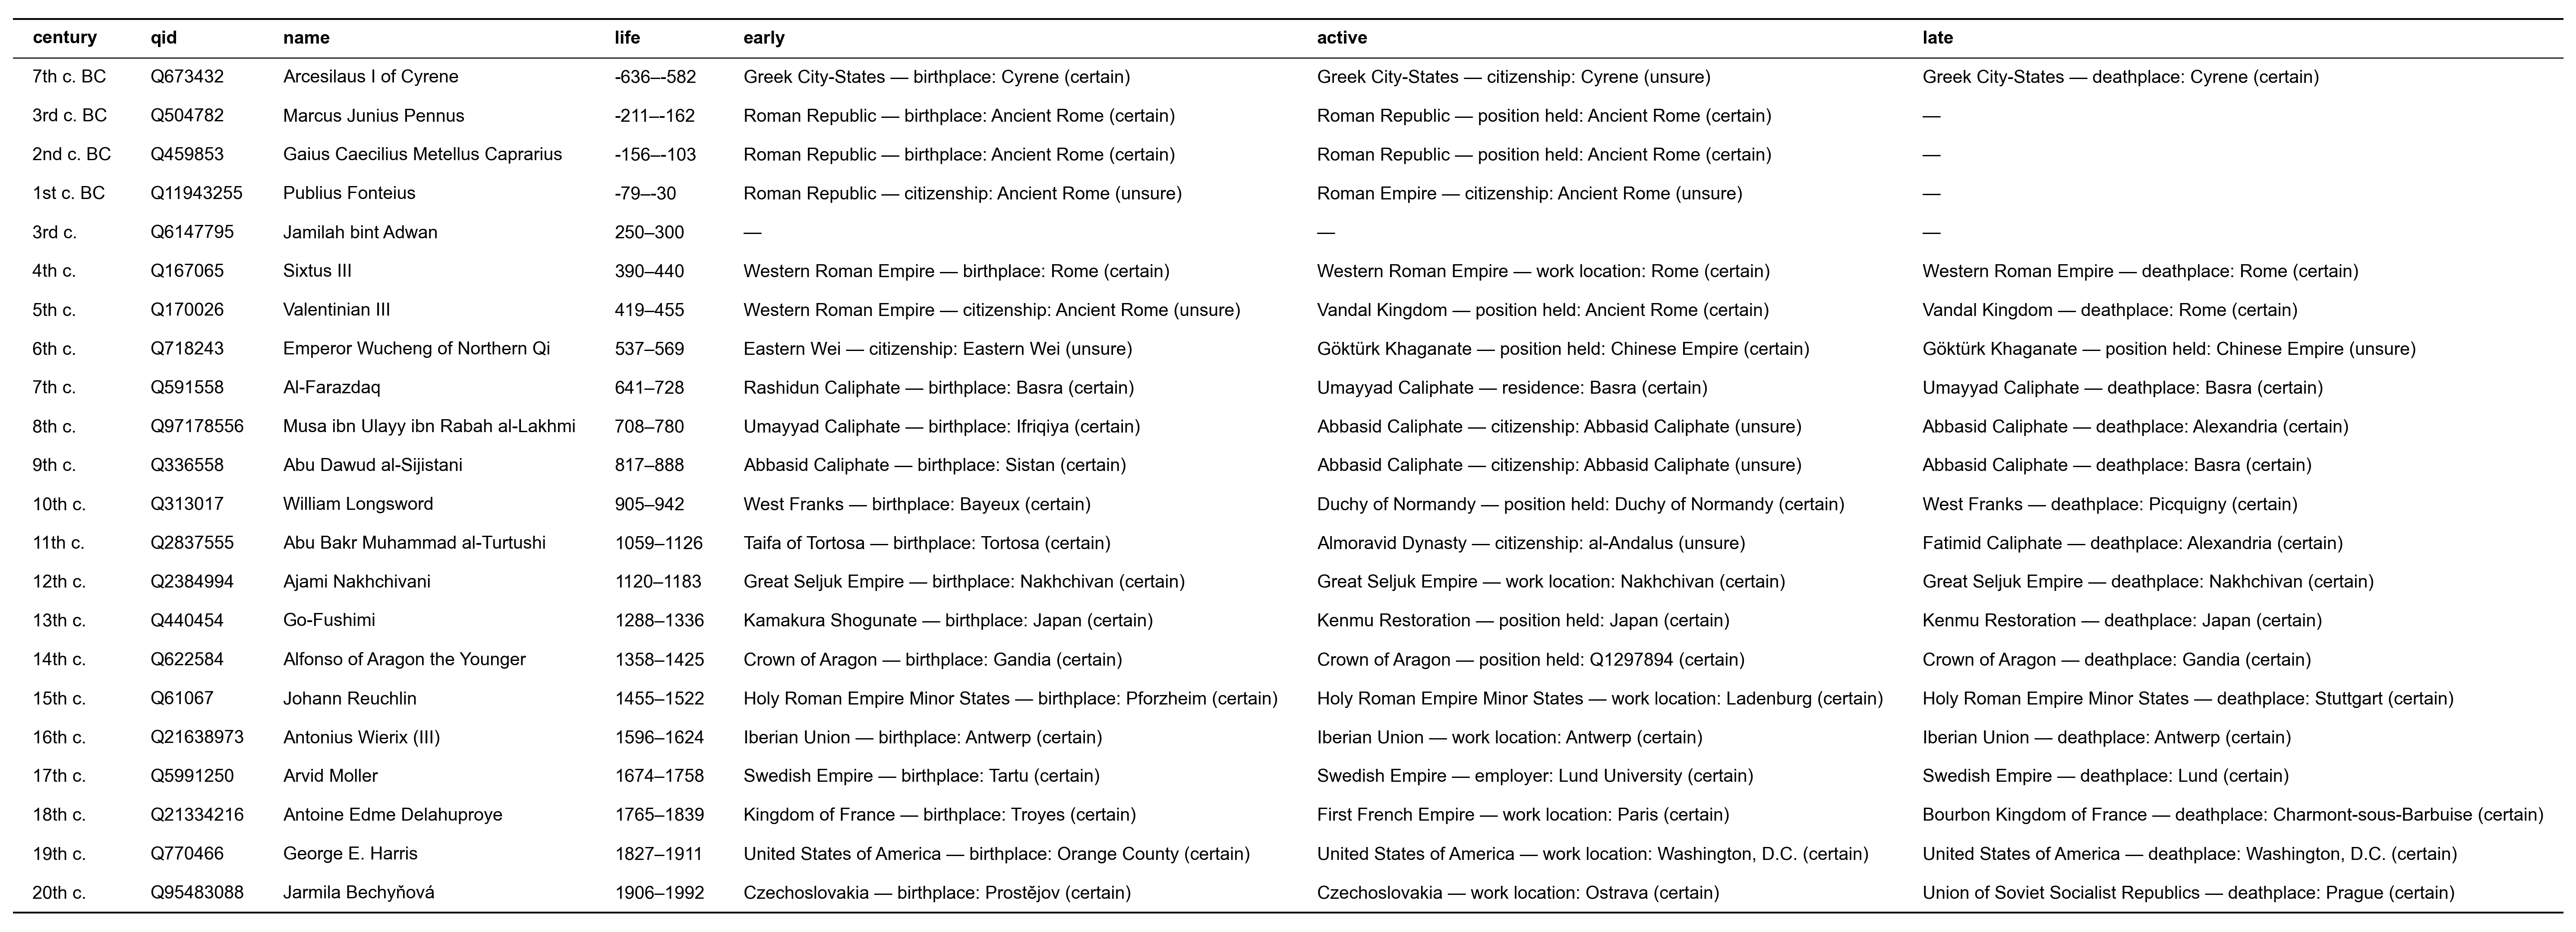

In [8]:
def century(year):
    number = abs(year) // 100 + 1 if year >= 0 else (abs(year) - 1) // 100 + 1
    suffix = 'th' if 10 <= number % 100 <= 20 else {1: 'st', 2: 'nd', 3: 'rd'}.get(number % 10, 'th')
    return f"{number}{suffix} c.{' BC' if year < 0 else ''}"


cells = assignments.with_columns(
    cell=pl.when(pl.col('polity').is_not_null()).then(pl.format('{} — {}: {} ({})', 'polity', 'rule', 'location', 'certainty')).otherwise(pl.lit('—'))
).pivot(on='stage', index='qid', values='cell')
matched = assignments.group_by('qid').agg((pl.col('certainty') != 'none').sum().alias('matched'), (pl.col('certainty') == 'certain').sum().alias('certain'))
per_century = (
    sample.select('qid', 'name', 'birth', 'death').drop_nulls('name')
    .join(cells, on='qid').join(matched, on='qid')
    .with_columns(order=pl.when(pl.col('birth') >= 0).then(pl.col('birth') // 100).otherwise(-((-pl.col('birth') - 1) // 100) - 1))
    .sort('order', 'matched', 'certain', pl.col('qid').hash(SEED), descending=[False, True, True, False])
    .unique('order', keep='first', maintain_order=True)
    .select(
        pl.col('birth').map_elements(century, return_dtype=pl.String).alias('century'),
        'qid', 'name', pl.format('{}–{}', 'birth', 'death').alias('life'), 'early', 'active', 'late',
    )
)
show_table(per_century, font_size=10)

### Tycho Brahe and Johannes Kepler

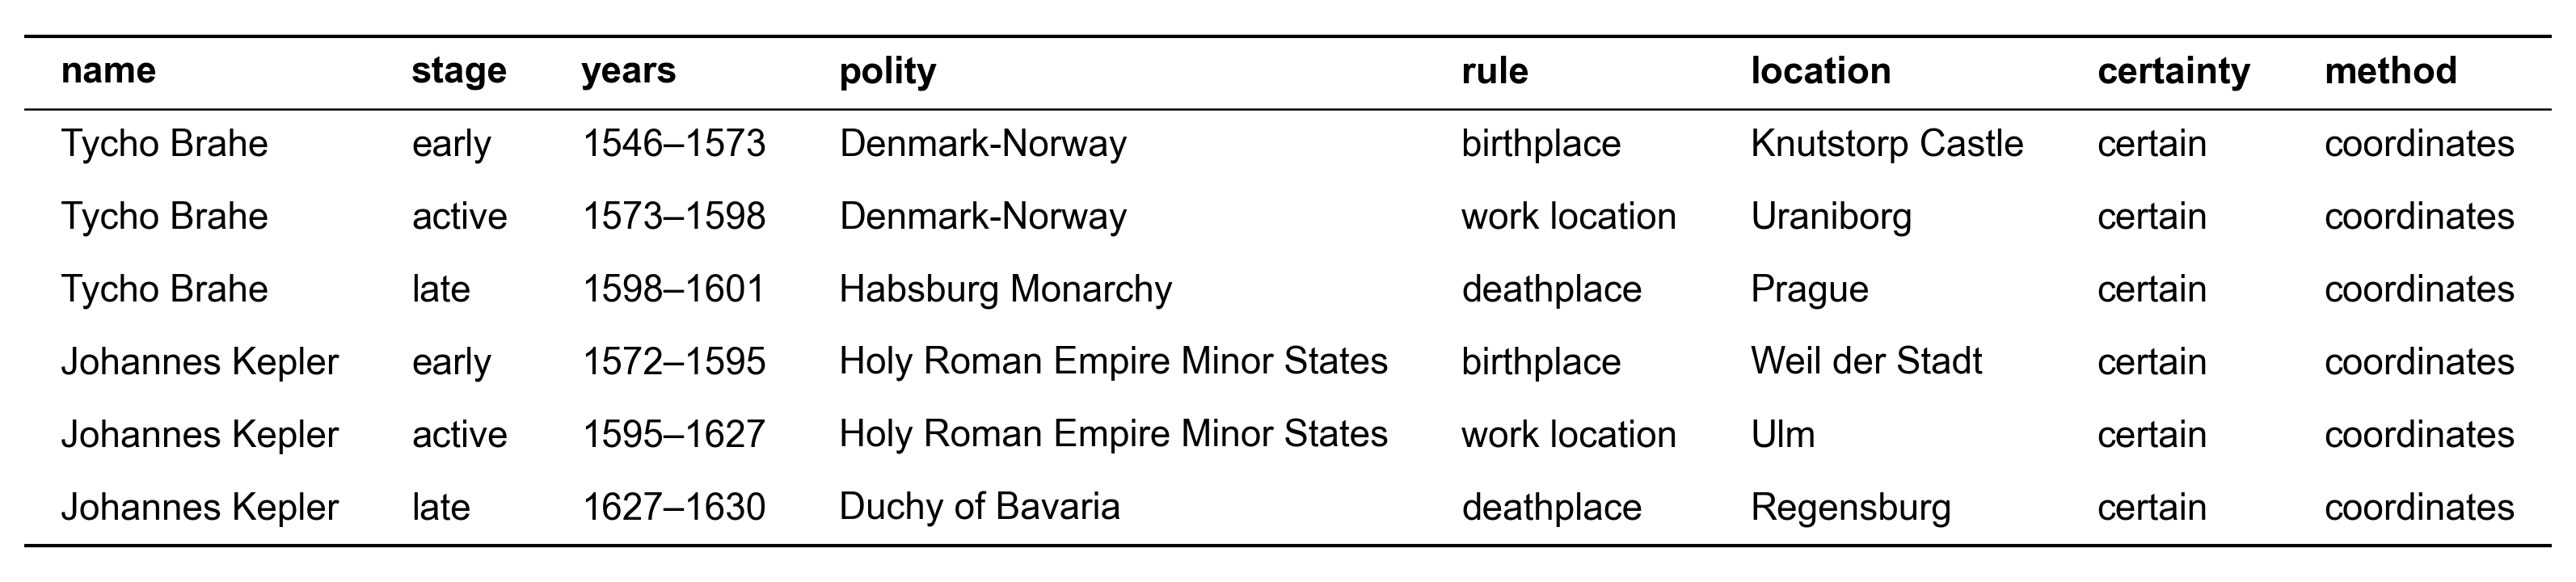

In [9]:
years = pl.when(pl.col('stage') == 'early').then(pl.format('{}–{}', 'birth', 'first_work')).when(pl.col('stage') == 'active').then(pl.format('{}–{}', 'first_work', 'last_work')).otherwise(pl.format('{}–{}', 'last_work', 'death'))
show_table(
    assignments.filter(pl.col('qid').is_in(EXAMPLES))
    .join(sample, on='qid')
    .sort('birth', pl.col('stage').cast(pl.Enum(list(STAGES))))
    .select('name', 'stage', years.alias('years'), 'polity', 'rule', 'location', 'certainty', 'method')
)